In [1]:
import pandas as pd
import numpy as np
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
from scipy import stats
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, Dataset
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm

import scipy.stats as st
from chronos import ChronosPipeline

# Предсказание модельного временного ряда с помощью ETS и NN

In [2]:
sigma = 1
sigma_a = np.sqrt(0.2)

train_len = 750
val_len = 250
test_len = 250

df = pd.read_csv('pc_br_series_new.csv')
n_realizations = df.shape[1]
series_len = df.shape[0]

first_series = df.iloc[:, 0].values

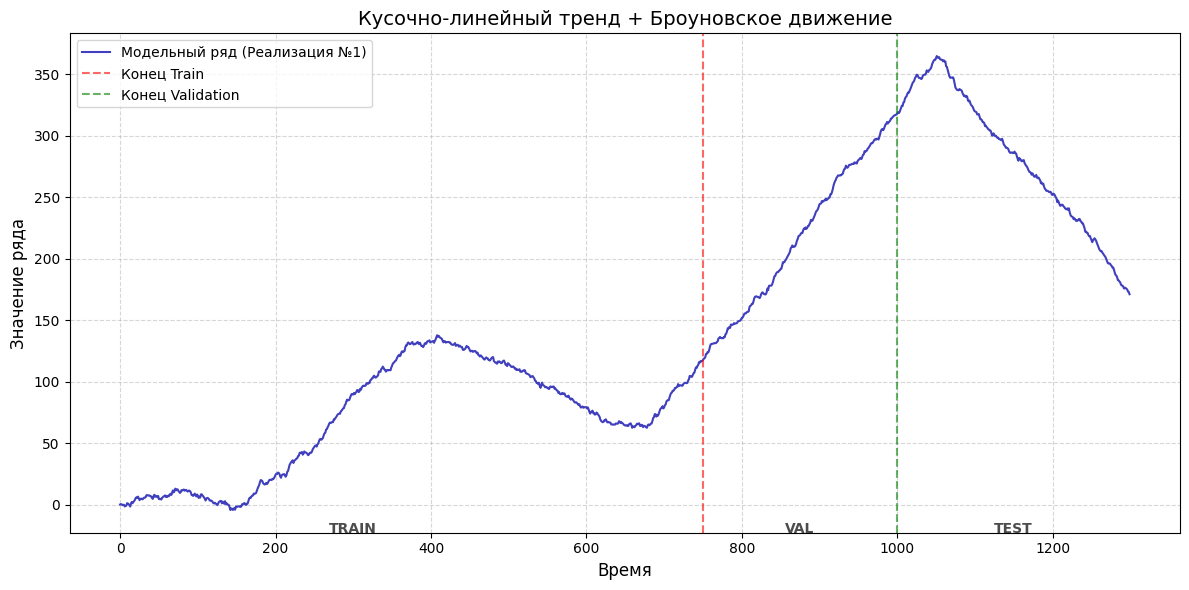

In [3]:
plt.figure(figsize=(12, 6))
plt.plot(first_series, color='#4040bf', linewidth=1.5, label='Модельный ряд (Реализация №1)')

plt.axvline(x=750, color='red', linestyle='--', alpha=0.6, label='Конец Train')
plt.axvline(x=1000, color='green', linestyle='--', alpha=0.6, label='Конец Validation')

plt.title('Кусочно-линейный тренд + Броуновское движение', fontsize=14)
plt.xlabel('Время', fontsize=12)
plt.ylabel('Значение ряда', fontsize=12)
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend()

plt.text(300, plt.ylim()[0], 'TRAIN', horizontalalignment='center', fontweight='bold', alpha=0.7)
plt.text(875, plt.ylim()[0], 'VAL', horizontalalignment='center', fontweight='bold', alpha=0.7)
plt.text(1150, plt.ylim()[0], 'TEST', horizontalalignment='center', fontweight='bold', alpha=0.7)

plt.tight_layout()
plt.show()

In [4]:
def get_confidence_interval(data):
    m = np.mean(data)
    se = stats.sem(data)
    h = se * 1.96
    return m, m - h, m + h

## ETS

In [5]:
all_mse_simp_ets = []

for i in range(n_realizations):
    series = df.iloc[:, i].values
    diff_series = np.diff(series)

    train_val_diff = diff_series[:train_len + val_len - 1]
    
    model_init = SimpleExpSmoothing(train_val_diff, initialization_method="estimated").fit()
    optimal_alpha = model_init.params['smoothing_level']
    
    test_errors = []
    
    current_level = model_init.level[-1]
    
    start_test_idx = train_len + val_len - 1
    
    for j in range(start_test_idx, len(diff_series)):
        diff_pred = current_level
        
        y_pred = series[j] + diff_pred
        y_true = series[j+1]
        test_errors.append((y_true - y_pred)**2)
        
        actual_diff = diff_series[j]
        current_level = optimal_alpha * actual_diff + (1 - optimal_alpha) * current_level

    all_mse_simp_ets.append(np.mean(test_errors))

mean_mse_ets, ci_low_ets, ci_high_ets = get_confidence_interval(all_mse_simp_ets)

print(f"\nРезультаты ETS:")
print(f"Средний MSE: {mean_mse_ets:.4f}")
print(f"Доверительный интервал: [{ci_low_ets:.4f}, {ci_high_ets:.4f}]")
print(f"Целевая вилка: [{sigma**2:.4f}, {sigma**2 + sigma_a**2:.4f}]")


Результаты ETS:
Средний MSE: 1.0529
Доверительный интервал: [1.0429, 1.0629]
Целевая вилка: [1.0000, 1.2000]


## NN

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Вычисления будут производиться на: {device}")

Вычисления будут производиться на: cuda


### MLP

In [7]:
class TimeSeriesDataset(Dataset):
    def __init__(self, series, window_size):
        self.X = []
        self.y = []

        for i in range(len(series) - window_size):
            self.X.append(series[i:i+window_size])
            self.y.append(series[i+window_size])
            
        self.X = torch.from_numpy(np.array(self.X)).float()
        self.y = torch.from_numpy(np.array(self.y)).float().view(-1, 1)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [8]:
class MLP(nn.Module):
    def __init__(self, input_size):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(input_size, 16)
        self.bn1 = nn.BatchNorm1d(16)
        self.dropout = nn.Dropout(0.1) 
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(16, 1)

    def forward(self, x):
        x = self.fc1(x)
        if x.size(0) > 1: x = self.bn1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return x

In [9]:
window_size = 30
batch_size = 100
n_epochs = 10
lr = 0.001

all_mse_nn = []

for i in tqdm(range(n_realizations)):
    series = df.iloc[:, i].values
    series_diff = np.diff(series)  
    
    split_idx = train_len + val_len 
    
    scaler = StandardScaler()
    train_val_diff_raw = series_diff[:split_idx - 1]
    train_val_diff_scaled = scaler.fit_transform(train_val_diff_raw.reshape(-1, 1)).flatten()
    series_diff_scaled = scaler.transform(series_diff.reshape(-1, 1)).flatten()

    train_dataset = TimeSeriesDataset(train_val_diff_scaled, window_size)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    
    model = MLP(window_size).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    criterion = nn.MSELoss()

    model.train()
    for epoch in range(n_epochs):
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)
            loss.backward()
            optimizer.step()


    model.eval()
    errors = []


    history_diff_scaled = series_diff_scaled[split_idx - 1 - window_size : split_idx - 1].tolist()

    test_len_mlp = series_len - split_idx
    for t in range(test_len_mlp):
        x_input = torch.tensor(history_diff_scaled[-window_size:], dtype=torch.float32).unsqueeze(0).to(device)
        
        with torch.no_grad():
            diff_pred_scaled = model(x_input).item()

        diff_pred_raw = scaler.inverse_transform([[diff_pred_scaled]])[0][0]

        y_prev_actual = series[split_idx - 1 + t]
        y_pred = y_prev_actual + diff_pred_raw
        y_true = series[split_idx + t]

        errors.append((y_true - y_pred)**2)

        actual_diff_scaled = series_diff_scaled[split_idx - 1 + t]
        history_diff_scaled.append(actual_diff_scaled)

    all_mse_nn.append(np.mean(errors))

100%|████████████████████████████████████████████████████████████████████████████████| 500/500 [02:24<00:00,  3.46it/s]


In [10]:
mean_mse_mlp, ci_low_mlp, ci_high_mlp = get_confidence_interval(all_mse_nn)

print("\nРезультаты MLP (полносвязная сеть):")
print(f"Средний MSE: {mean_mse_mlp:.4f}")
print(f"Доверительный интервал: [{ci_low_mlp:.4f}, {ci_high_mlp:.4f}]")
print(f"Целевая вилка: [{sigma**2:.4f}, {sigma**2 + sigma_a**2:.4f}]")


Результаты MLP (полносвязная сеть):
Средний MSE: 1.1291
Доверительный интервал: [1.1108, 1.1474]
Целевая вилка: [1.0000, 1.2000]


### Предобученная 

In [11]:
context_len = 50  

pipeline = ChronosPipeline.from_pretrained(
    "amazon/chronos-t5-tiny",
    device_map=device,
    torch_dtype=torch.float32,
)

all_series = df.values.T 
all_diffs = np.diff(all_series, axis=1) 

all_diffs_tensor = torch.tensor(all_diffs, dtype=torch.float32)

split_idx = train_len + val_len
start_test_idx = split_idx - 1
test_len_ch = series_len - split_idx

squared_errors = np.zeros((n_realizations, test_len_ch))


for t in tqdm(range(test_len_ch)):
    
    current_idx = start_test_idx + t
    
    context_batch = all_diffs_tensor[:, current_idx - context_len : current_idx]
    
    with torch.no_grad():
        forecast = pipeline.predict(
            context_batch,
            prediction_length=1,
            num_samples=1,
            limit_prediction_length=False
        )
       
    diff_pred = forecast[:, 0, 0].cpu().numpy()
    y_prev_actual = all_series[:, current_idx] 
    y_pred = y_prev_actual + diff_pred
    
    y_true = all_series[:, current_idx + 1]

    squared_errors[:, t] = (y_true - y_pred)**2

mse_per_realization = np.mean(squared_errors, axis=1)

`torch_dtype` is deprecated! Use `dtype` instead!
100%|████████████████████████████████████████████████████████████████████████████████| 300/300 [00:23<00:00, 12.93it/s]


In [24]:
mean_mse_hf, ci_low_hf, ci_high_hf = get_confidence_interval(mse_per_realization)

print(f"\nРезультаты Pretrained (Chronos):")
print(f"Средний MSE: {mean_mse_hf:.4f}")
print(f"Доверительный интервал: [{ci_low_hf:.4f}, {ci_high_hf:.4f}]")
print(f"Целевая вилка: [{sigma**2:.4f}, {sigma**2 + sigma_a**2:.4f}]")


Результаты Pretrained (Chronos):
Средний MSE: 1.1232
Доверительный интервал: [1.1133, 1.1330]
Целевая вилка: [1.0000, 1.2000]


## Сравнение MSE прогнозов 

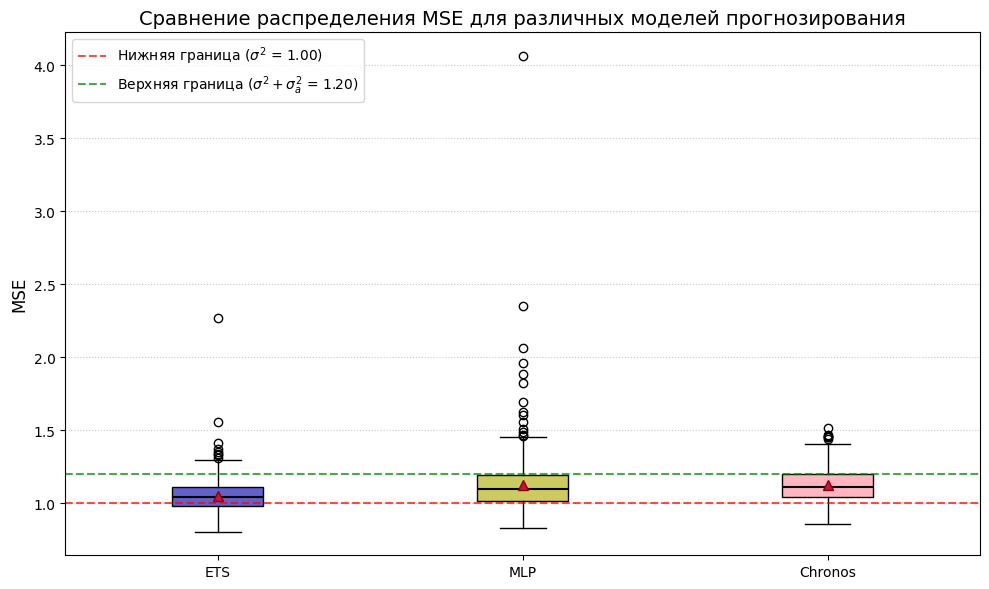

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))

data_to_plot = [all_mse_simp_ets, all_mse_nn, mse_per_realization]
labels = ['ETS', 'MLP', 'Chronos']

bplot = ax.boxplot(data_to_plot, 
                   patch_artist=True,  
                   tick_labels=labels, 
                   showmeans=True, 
                   meanline=False,
                   medianprops={'color': 'black', 'linewidth': 1.5},  
                   meanprops={'marker': '^', 'markerfacecolor': '#c41345',  
                              'markeredgecolor': 'darkred', 'markersize': 7})   


colors = ['#6262cb', '#cbcb62', '#FFB6C1'] 
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)


lower_bound = sigma**2
upper_bound = sigma**2 + sigma_a**2

ax.axhline(y=lower_bound, color='red', linestyle='--', alpha=0.7, 
           label=f'Нижняя граница ($\\sigma^2$ = {lower_bound:.2f})')
ax.axhline(y=upper_bound, color='green', linestyle='--', alpha=0.7, 
           label=f'Верхняя граница ($\\sigma^2 + \\sigma_a^2$ = {upper_bound:.2f})')

ax.set_title('Сравнение распределения MSE для различных моделей прогнозирования', fontsize=14)
ax.set_ylabel('MSE', fontsize=12)
ax.grid(axis='y', linestyle=':', alpha=0.7)
ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

## Сравнение доверительных интервалов

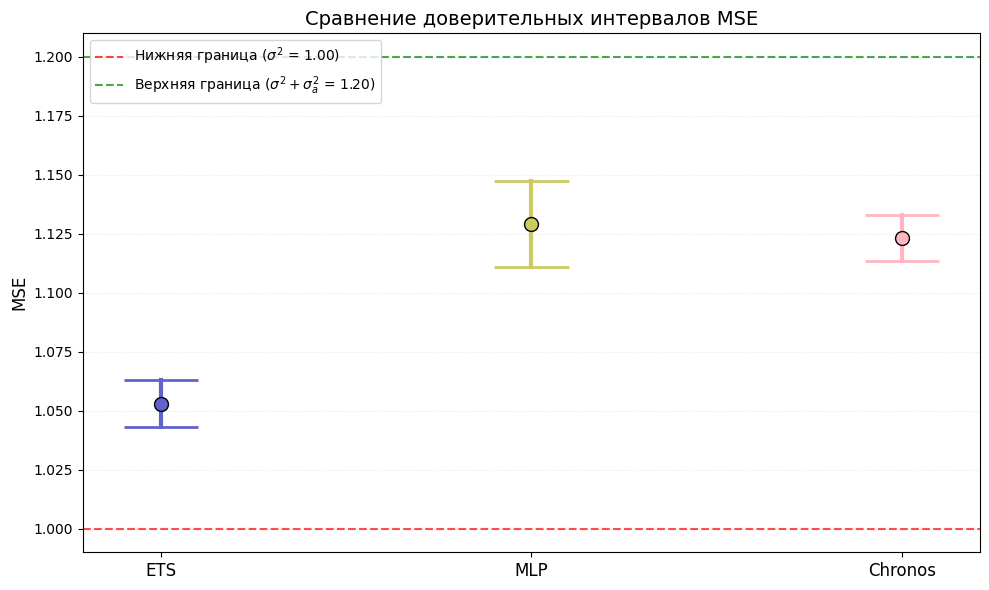

In [23]:
fig, ax = plt.subplots(figsize=(10, 6))

models = ['ETS', 'MLP', 'Chronos']

means = [mean_mse_ets, mean_mse_mlp, mean_mse_hf]
ci_lows = [ci_low_ets, ci_low_mlp, ci_low_hf]
ci_highs = [ci_high_ets, ci_high_mlp, ci_high_hf]

colors = ['#6262cb', '#cbcb62', '#FFB6C1']

x_pos = np.arange(len(models))

for i, (mean, ci_low, ci_high, color) in enumerate(zip(means, ci_lows, ci_highs, colors)):
    ax.plot([i, i], [ci_low, ci_high], color=color, linewidth=3)
    
    ax.hlines(y=ci_low, xmin=i-0.1, xmax=i+0.1, color=color, linewidth=2)
    ax.hlines(y=ci_high, xmin=i-0.1, xmax=i+0.1, color=color, linewidth=2)
    
    ax.plot(i, mean, 'o', color=color, markersize=10,
            markeredgecolor='black', markeredgewidth=1, zorder=5)

ax.axhline(y=lower_bound, color='red', linestyle='--', alpha=0.7, 
           label=f'Нижняя граница ($\\sigma^2$ = {lower_bound:.2f})')
ax.axhline(y=upper_bound, color='green', linestyle='--', alpha=0.7, 
           label=f'Верхняя граница ($\\sigma^2 + \\sigma_a^2$ = {upper_bound:.2f})')

ax.set_xticks(x_pos)
ax.set_xticklabels(models, fontsize=12)
ax.set_ylabel('MSE', fontsize=12)
ax.set_title('Сравнение доверительных интервалов MSE', fontsize=14)
ax.grid(axis='y', linestyle=':', alpha=0.3)
ax.legend(loc='upper left', fontsize=10)

plt.tight_layout()
plt.show()